# CreditScope — Home Credit Case

**Lucas Menghi** · classificação binária de dificuldade de pagamento. Continuação do projeto de ingestão Oracle [Case Default Risk](https://github.com/lucasmenghi/Case_Default_Risk).

O alvo segue a definição original da competição; não é uma definição universal de default. Não há validação temporal nem decisão automática de crédito.

In [1]:
from pathlib import Path
import json, pandas as pd
from IPython.display import display, Image
ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
def report(name): return json.loads((ROOT / 'reports' / name).read_text())
manifest = report('data_manifest.json')
display(manifest)

{'source': 'https://www.kaggle.com/competitions/home-credit-default-risk/data',
 'source_sha256': '4e7a243b13f6e3d40f682a9a0cfd59c70910ca6c5a4289f71ca1f25efbd8e3de',
 'rows': 307511,
 'positives': 24825,
 'target_description': 'Target variable (1 - client with payment difficulties: he/she had late payment more than X days on at least one of the first Y installments of the loan in our sample, 0 - all other cases)',
 'splits': {'calibration': 30751,
  'development': 30751,
  'policy': 15375,
  'test': 46128,
  'train': 184506},
 'target_rates': {'calibration': 0.08074534161490683,
  'development': 0.08071282234724074,
  'policy': 0.08071544715447154,
  'test': 0.08073187651751648,
  'train': 0.08072908198107379},
 'date_audit': {'bureau_rows': 1716428,
  'bureau_excluded_future_or_unknown': 17,
  'previous_rows': 1670214,
  'previous_excluded': 0,
  'installment_rows': 13605401,
  'installment_excluded_future_or_missing': 2905},
 'etl_bridge': {'available': True,
  'rows': 307511,
  'sam

## 1. Dados e ponte com o ETL
307.511 aplicações rotuladas. Comparação dos clientes e dos alvos com o parquet do ETL original. Histórico com datas relativas anteriores ou iguais à aplicação; pagamentos futuros ou sem data excluídos. Fotos retrospectivas ainda não comprovam disponibilidade operacional.

In [2]:
display(manifest['etl_bridge'])
display(manifest['date_audit'])
display(pd.DataFrame({'n': manifest['splits'], 'positive_rate': manifest['target_rates']}))

{'available': True,
 'rows': 307511,
 'same_customer_ids': True,
 'same_targets': True}

{'bureau_rows': 1716428,
 'bureau_excluded_future_or_unknown': 17,
 'previous_rows': 1670214,
 'previous_excluded': 0,
 'installment_rows': 13605401,
 'installment_excluded_future_or_missing': 2905}

,n,positive_rate
calibration,30751,0.080745
development,30751,0.080713
policy,15375,0.080715
test,46128,0.080732
train,184506,0.080729


## 2. Preparação e seleção
Separação estratificada por cliente: 60% treino, 10% desenvolvimento, 10% calibração, 5% política e 15% teste final. Imputação e escala da regressão ajustadas somente no treino. LightGBM trata ausentes; categorias desconhecidas têm código reservado. Gênero e identificador não entram no modelo. DAYS_EMPLOYED=365243 é sentinela, não tempo de emprego.

,model,average_precision,roc_auc
0,logistic_c01,0.218015,0.741441
1,logistic_c1,0.218198,0.741260
2,lightgbm_15,0.243494,0.757953
3,lightgbm_31,0.247341,0.760446


{'seed': 42,
 'candidates': {'logistic_c01': {'kind': 'logistic', 'C': 0.1},
  'logistic_c1': {'kind': 'logistic', 'C': 1},
  'lightgbm_15': {'kind': 'lightgbm', 'leaves': 15, 'trees': 300},
  'lightgbm_31': {'kind': 'lightgbm', 'leaves': 31, 'trees': 450}},
 'selected': 'lightgbm_31',
 'selection': 'Highest average precision in separate stratified development customers; single split, no cross-validation claim',
 'split_sizes': {'calibration': 30751,
  'development': 30751,
  'policy': 15375,
  'test': 46128,
  'train': 184506},
 'threshold_rule': '80th percentile of calibrated policy scores, frozen before final test',
 'thresholds': {'selected': 0.1168494696132467,
  'logistic_baseline': 0.11762497155218293},
 'raw_inputs': ['NAME_CONTRACT_TYPE',
  'NAME_INCOME_TYPE',
  'NAME_EDUCATION_TYPE',
  'NAME_HOUSING_TYPE',
  'AMT_INCOME_TOTAL',
  'AMT_CREDIT',
  'AMT_ANNUITY',
  'AMT_GOODS_PRICE',
  'DAYS_BIRTH',
  'DAYS_EMPLOYED',
  'CNT_CHILDREN',
  'REGION_RATING_CLIENT',
  'EXT_SOURCE_1',

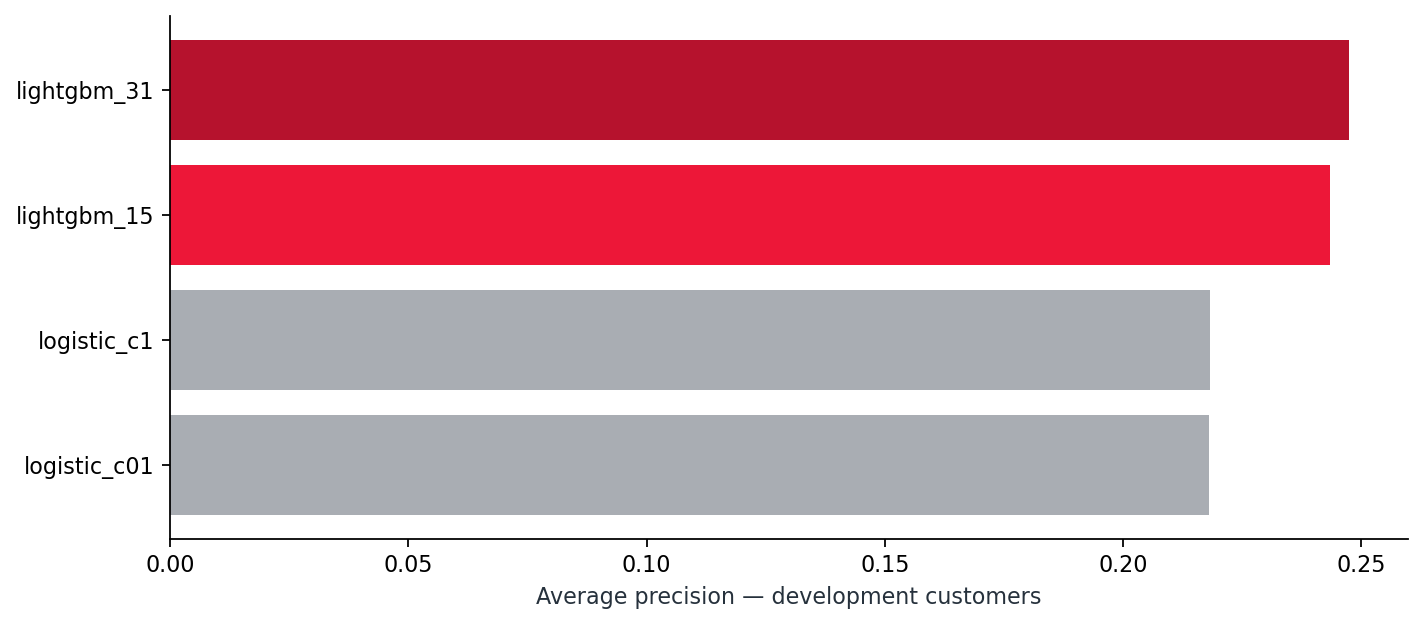

In [3]:
display(pd.read_csv(ROOT/'reports/development.csv'))
display(report('frozen_config.json'))
display(Image(filename=str(ROOT/'reports/figures/development.png')))

## 3. Teste final e calibração
Seleção por average precision no desenvolvimento. Platt scaling em clientes independentes; percentil 80 em outra partição para o limiar. O teste só é pontuado depois do congelamento. ROC AUC, AP, KS, Brier e capacidade de análise são reportados.

,average_precision,roc_auc,brier,ks,threshold,precision,recall,queue_rate,precision_at20,recall_at20,lift_at20,confusion_matrix
selected,0.25471,0.764241,0.067323,0.395667,0.116849,0.210269,0.531149,0.203933,0.211901,0.524973,2.624752,"[[34975, 7429], [1746, 1978]]"
logistic_baseline,0.234742,0.749205,0.068301,0.375622,0.117625,0.201979,0.515306,0.20597,0.204639,0.506982,2.534799,"[[34822, 7582], [1805, 1919]]"


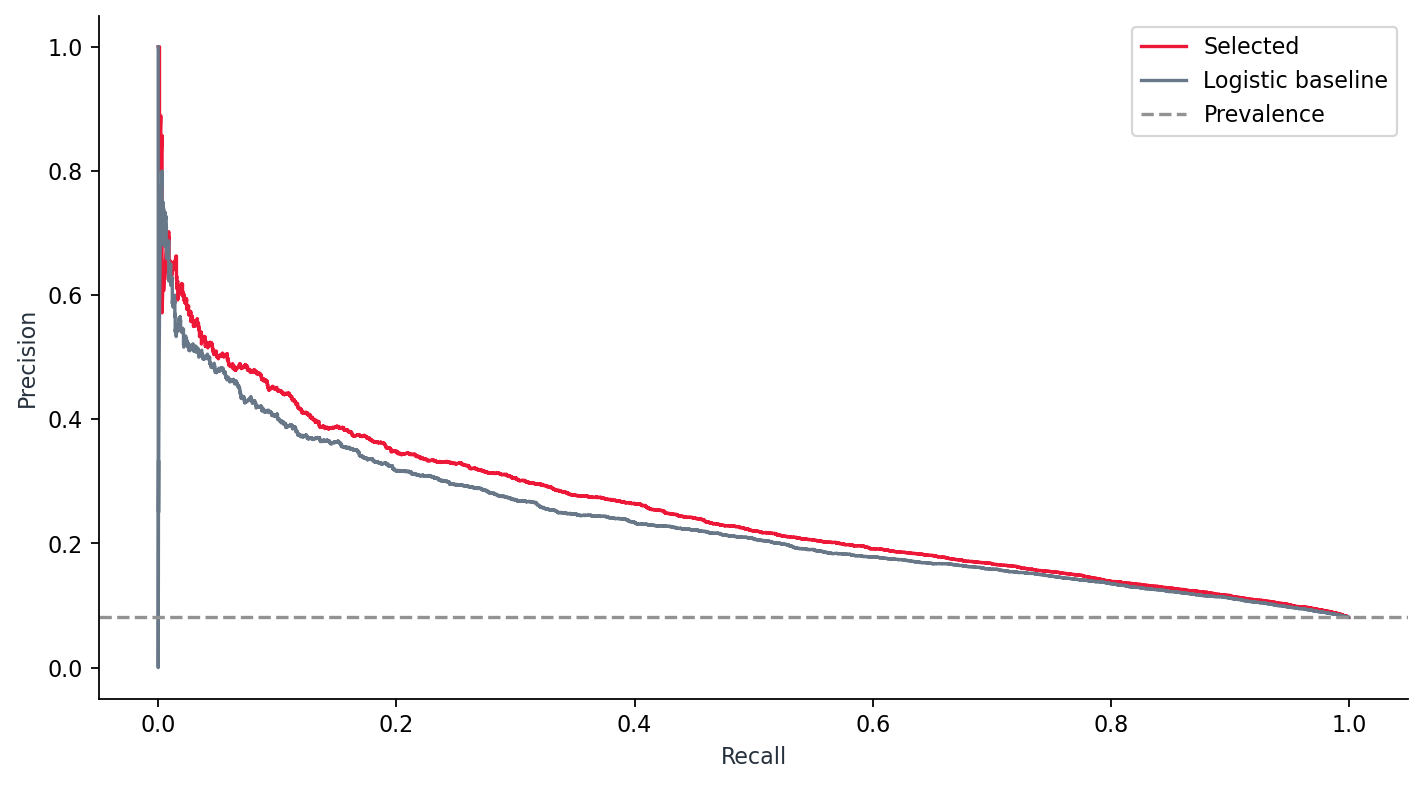

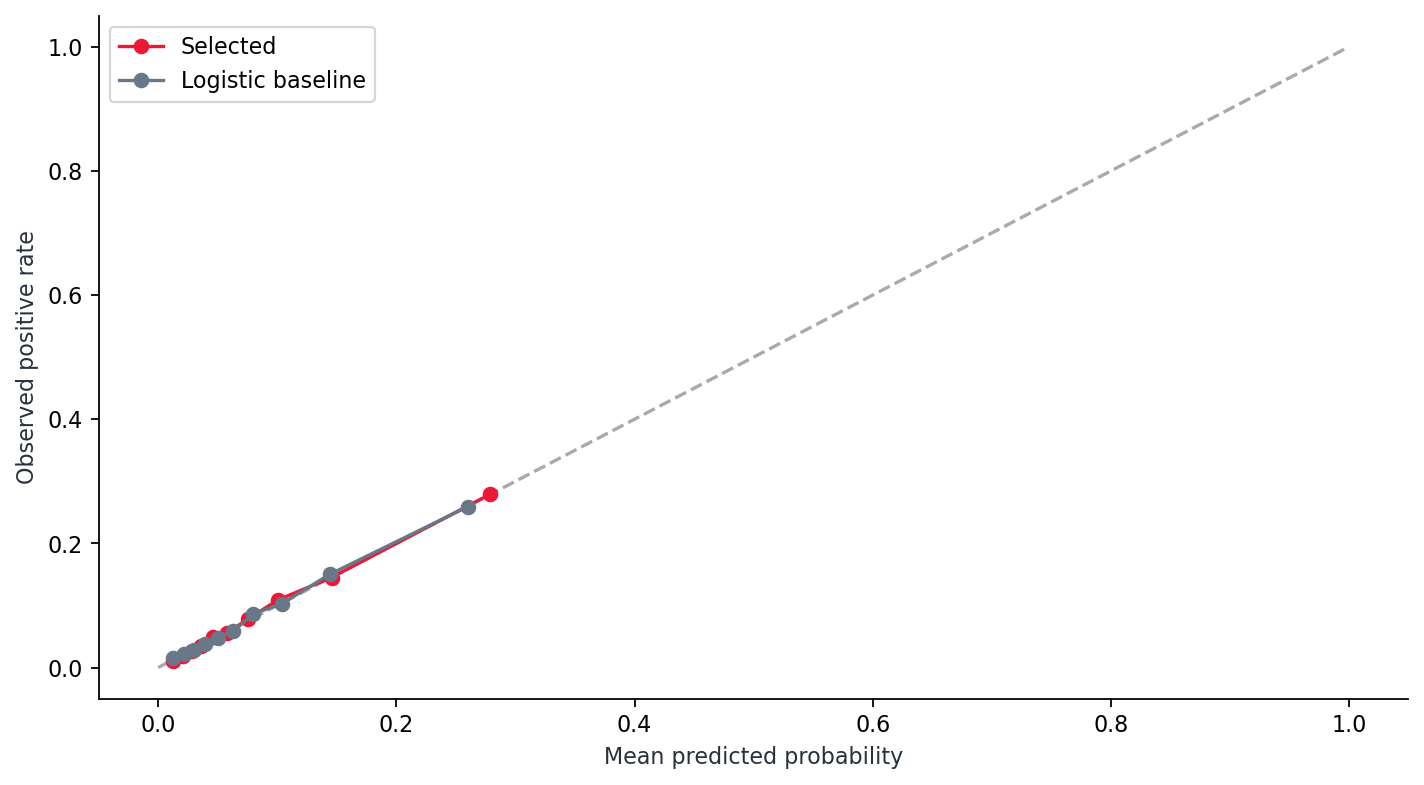

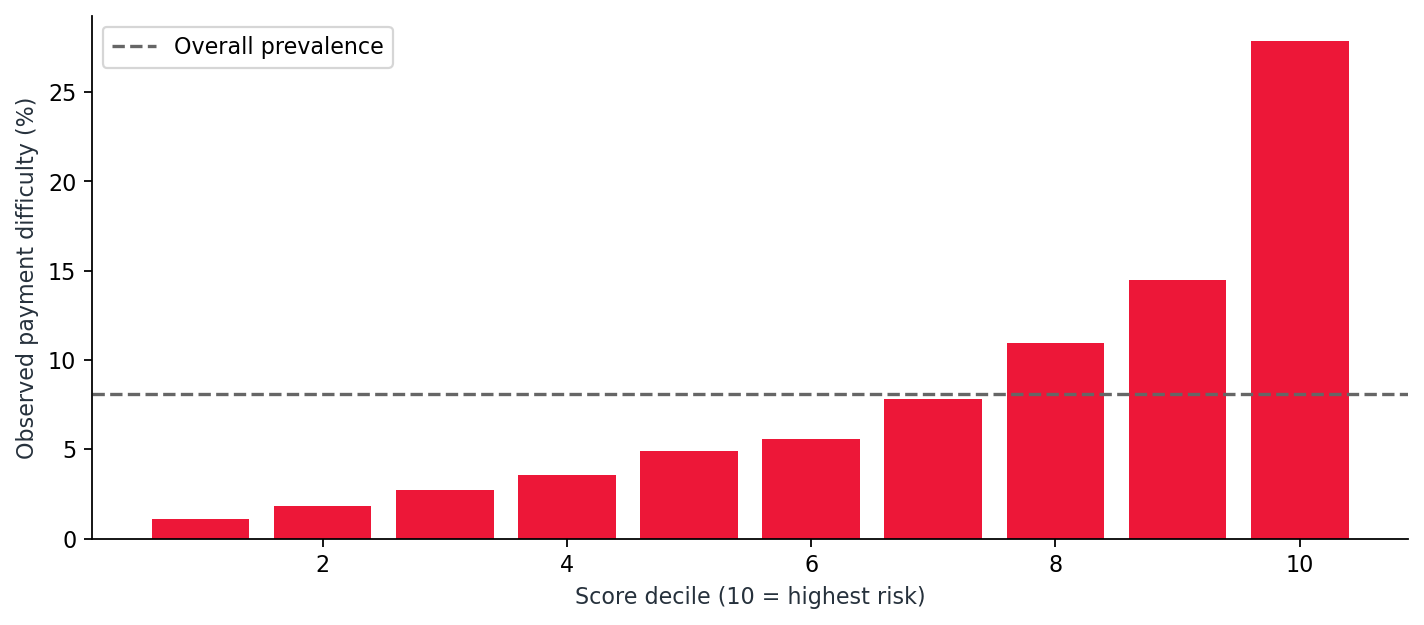

In [4]:
metrics=report('metrics.json')
display(pd.DataFrame({k:metrics[k] for k in ['selected','logistic_baseline']}).T)
for name in ['precision_recall','calibration','risk_deciles']: display(Image(filename=str(ROOT/f'reports/figures/{name}.png')))

## 4. Cenários de capacidade
Top 20% por ranking e limiar congelado são análises distintas. A capacidade histórica não prova redução de inadimplência, lucro ou retorno sobre investimento.

In [5]:
display(pd.DataFrame([{**{'capacity_pct':r['capacity']}, **r['selected']} for r in report('capacity_scenarios.json')]))

,capacity_pct,queue,identified,precision,recall,lift
0,5,2307,791,0.342870,0.212406,4.247015
1,10,4613,1286,0.278777,0.345328,3.453126
2,15,6920,1670,0.241329,0.448443,2.989271
3,20,9226,1955,0.211901,0.524973,2.624752
4,30,13839,2459,0.177686,0.660311,2.200943
5,40,18452,2820,0.152829,0.757250,1.893044
6,50,23064,3076,0.133368,0.825994,1.651987


## 5. Auditoria e limitações
Gênero excluído das features, mantido apenas para diagnóstico. Excluir uma variável sensível não demonstra equidade: há proxies. Idade permanece no modelo e exige revisão para aplicação real. Scores externos são anonimizados e não têm explicação operacional. Validar tempo, drift, disponibilidade, estabilidade e impactos antes de um piloto com humanos.

,group,n,prevalence,average_precision,roc_auc,brier,ks,threshold,precision,recall,queue_rate,precision_at20,recall_at20,lift_at20,confusion_matrix
0,F,30474,0.069732,0.232161,0.755877,0.059485,0.378361,0.116849,0.192908,0.488941,0.176741,0.183429,0.526118,2.630502,"[[24002, 4347], [1086, 1039]]"
1,M,15654,0.102146,0.285670,0.766534,0.082581,0.403545,0.116849,0.233524,0.587242,0.256867,0.260939,0.510944,2.554559,"[[10973, 3082], [660, 939]]"


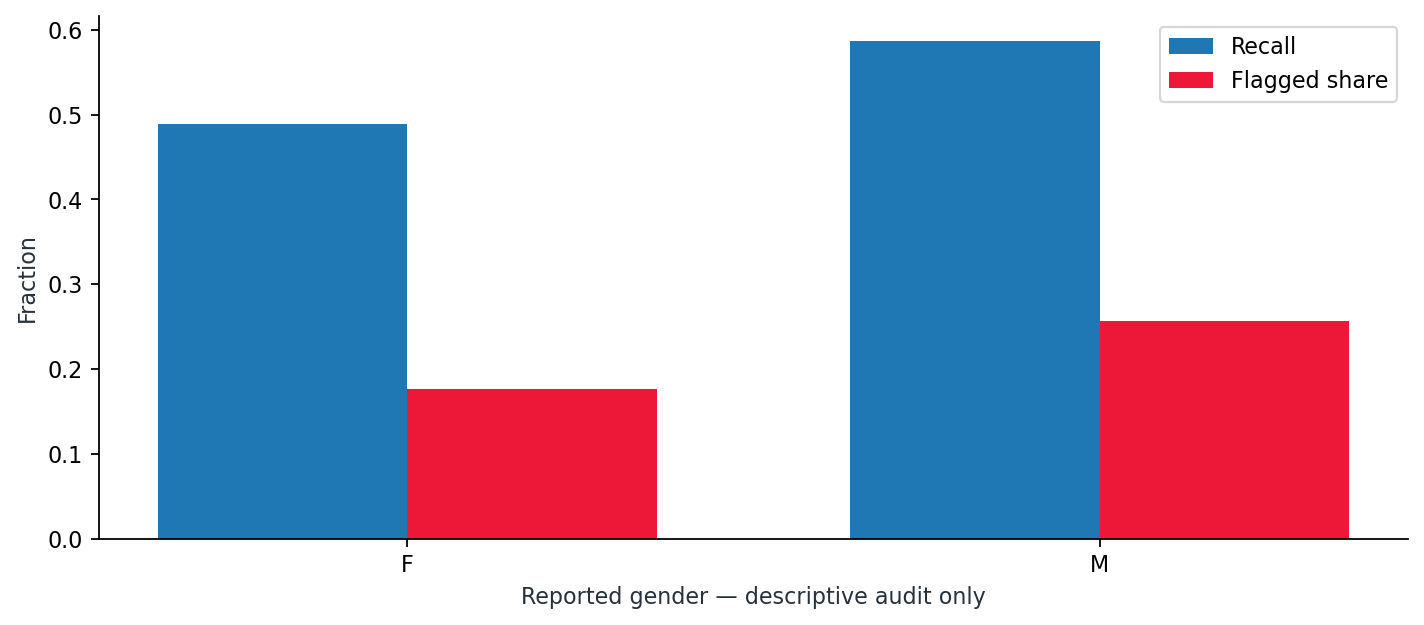

In [6]:
display(pd.DataFrame(report('subgroups.json')))
display(Image(filename=str(ROOT/'reports/figures/subgroups.png')))

## 6. Reprodução
Baixe a fonte original respeitando os termos da competição. O repositório publica artefatos agregados e modelos, sem redistribuir os CSVs ou previsões individuais.
```bash
python scripts/prepare.py --source /path/home-credit-default-risk.zip
python scripts/train.py
python scripts/build_report.py
streamlit run app.py
```